# 03 · Species-level evolution

**Author:** Yike SHI

**Question 3 of the brief.** Which species changed, by how much, how sure are we, and why might
it be? We (1) select species with an explicit rule, (2) compute zero-filled standardised indices
and occurrence rates with confidence intervals, (3) estimate a global rate of change with two
estimators and classify each species, and (4) discuss ecological and operational explanations
as hypotheses.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from src import config as C, indices as I, models as M, species as S, plots

plots.set_style()
pd.set_option("display.width", 160)
B = 1000

records = pd.read_csv(C.PROCESSED_DIR / "records.csv.gz", low_memory=False)
visits = pd.read_csv(C.PROCESSED_DIR / "visits.csv", parse_dates=["date"])
point_visits = pd.read_csv(C.PROCESSED_DIR / "point_visits.csv.gz")
rec = records[records["is_record"] == True].copy()
rec["is_species"] = rec["is_species"].astype(bool)
sp_rec = rec[rec["is_species"]]

# Visit-level covariates (same construction as notebook 02)
wx = (records.drop_duplicates(["visit_id", "point"]).groupby("visit_id")
      .agg(rain_share=("rain", lambda s: (s >= 2).mean()), wind_share=("wind", lambda s: (s == 3).mean())))
v = visits.merge(wx, on="visit_id", how="left")
v["doy_c"] = v["doy"] - v["doy"].mean()
v["start_h"] = ((v["start_min"] - 360) / 60).fillna(((v["start_min"] - 360) / 60).median())
v["p2"] = (v["passage"] == 2).astype(float)
v[["rain_share", "wind_share"]] = v[["rain_share", "wind_share"]].fillna(0)
COND = ["doy_c", "start_h", "p2", "rain_share", "wind_share"]
TR = sorted(point_visits["transect"].unique())
YRS = sorted(point_visits["year"].unique())
W = I.cluster_weights(len(TR), B, C.SEED)       # one set of transect weights shared by all species

## 1. Which species?

**Selection rule** (fixed before looking at trends, to avoid choosing species *because* they
changed):

1. *Trend set*: breeding-season residents (seabirds and migrants excluded — the April–June
   survey is not designed for them) detected in **≥ 200 point counts** and in **all 12 years**,
   and present on **≥ 10 transects** (fewer sites make the transect bootstrap meaningless).
2. *Conservation additions*: the two **Martinique endemics** are always included and discussed,
   even if they fail rule 1, because they are the island's main conservation responsibility.

Eight **focal species** are shown in detail: the most frequent species, endemic species of
conservation interest, and the exotic species that drive the composition change found in
notebook 02.

In [2]:
info = (sp_rec.groupby("species")
        .agg(name_sci=("name_sci", "first"), status=("status", "first"), group=("status_group", "first"),
             detections=("point", "size"), individuals=("count", "sum"),
             years=("year", "nunique"), transects=("transect", "nunique")))
info["pct_point_counts"] = (info["detections"] / len(point_visits) * 100).round(1)
rule1 = (info["detections"] >= 200) & (info["years"] == 12) & (info["transects"] >= 10) \
        & ~info["group"].isin(["Seabird", "Migrant"])
mq_endemics = info.index[info["status"].eq("Endemic (Martinique)")].tolist()
trend_set = info.index[rule1].tolist()
analysed = sorted(set(trend_set) | set(mq_endemics))
FOCAL = ["Sucrier à ventre jaune", "Sporophile rougegorge", "Colibri madère", "Colibri falle-vert",
         "Oriole de Martinique", "Moqueur gorge blanche", "Tourterelle turque", "Vacher luisant"]
assert set(FOCAL) <= set(analysed)
print(f"Trend set: {len(trend_set)} species; Martinique endemics added: "
      f"{[s for s in mq_endemics if s not in trend_set]}")
info.loc[analysed].sort_values("detections", ascending=False)[
    ["name_sci", "status", "detections", "pct_point_counts", "transects"]]

Trend set: 34 species; Martinique endemics added: ['Moqueur gorge blanche']


,name_sci,status,detections,pct_point_counts,transects
species,,,,,
Sucrier à ventre jaune,Coereba flaveola martinicana,Native,10880,77.0,65
Elénie siffleuse,Elaenia m. martinica,Native,9658,68.4,65
Sporophile rougegorge,Loxigilla n. noctis,Endemic (Lesser Antilles),9168,64.9,65
Tourterelle à queue carrée,Zenaida a. aurita,Native,8811,62.4,64
Quiscale merle,Quiscalus lugubris guadeloupensis,Native,8662,61.3,65
Tyran gris,Tyrannus dominicensis vorax,Native,7324,51.8,65
Saltator gros-bec,Saltator a. albicollis,Native,6767,47.9,65
Sporophile cici,Melanospiza bicolor,Native,6351,45.0,65
Viréo à moustaches,Vireo altiloquus barbadensis,Native,5843,41.4,62


## 2. Standardised indices, absences and uncertainty

For species *s* and year *t*: **index = individuals of *s* / point counts surveyed in *t***.
Every surveyed point is in the denominator, including the (majority of) points where *s* was not
recorded: an absence is a **true zero, not a missing value**. Averaging only over points where
the species was seen would estimate a different, much larger quantity (abundance *given*
presence) and would hide changes in how widespread a species is.

The base-100 index is expressed relative to the **multi-year mean** rather than to 2014: a single
base year carries its own sampling error into every value of the series (and 2014 is the
ramp-up year), whereas the 12-year mean is far more precise — a variance argument.
CIs: cluster bootstrap over transects, B = 1000.

In [3]:
P = S.point_species_table(sp_rec, point_visits, analysed)
print("Sanity: zero-filled table has one row per point count:", len(P) == len(point_visits),
      "| totals preserved:", np.isclose(P[analysed].to_numpy().sum(),
                                         sp_rec.loc[sp_rec["species"].isin(analysed), "count"].sum()))
ex = "Oriole de Martinique"
print(f"Illustration ({ex}): mean over all point counts = {P[ex].mean():.3f}; "
      f"mean over points where it was seen = {P.loc[P[ex] > 0, ex].mean():.2f} "
      f"(the second ignores the {(P[ex] == 0).mean():.1%} true zeros)")

series = {}
for sp in analysed:
    est, reps = S.annual_index_series(P, sp, W, TR, YRS)
    rel = est / est.mean() * 100
    # a replicate that drew none of a very local species' transects has index 0 in every year:
    # its relative index is undefined (0/0) and is dropped (only happens for Moqueur gorge blanche)
    mean_b = reps.mean(1, keepdims=True)
    rel_reps = np.divide(reps, mean_b, out=np.full_like(reps, np.nan), where=mean_b > 0) * 100
    lo, hi = I.percentile_ci(rel_reps)
    series[sp] = pd.DataFrame({"index": est, "index100": rel, "low": lo, "high": hi}, index=YRS)
idx_tab = pd.concat({sp: series[sp]["index100"] for sp in analysed}, axis=1).T.round(1)
idx_tab.to_csv(C.RES_DIR / "table15_species_index100.csv")

Sanity: zero-filled table has one row per point count: True | totals preserved: True
Illustration (Oriole de Martinique): mean over all point counts = 0.020; mean over points where it was seen = 1.24 (the second ignores the 98.4% true zeros)


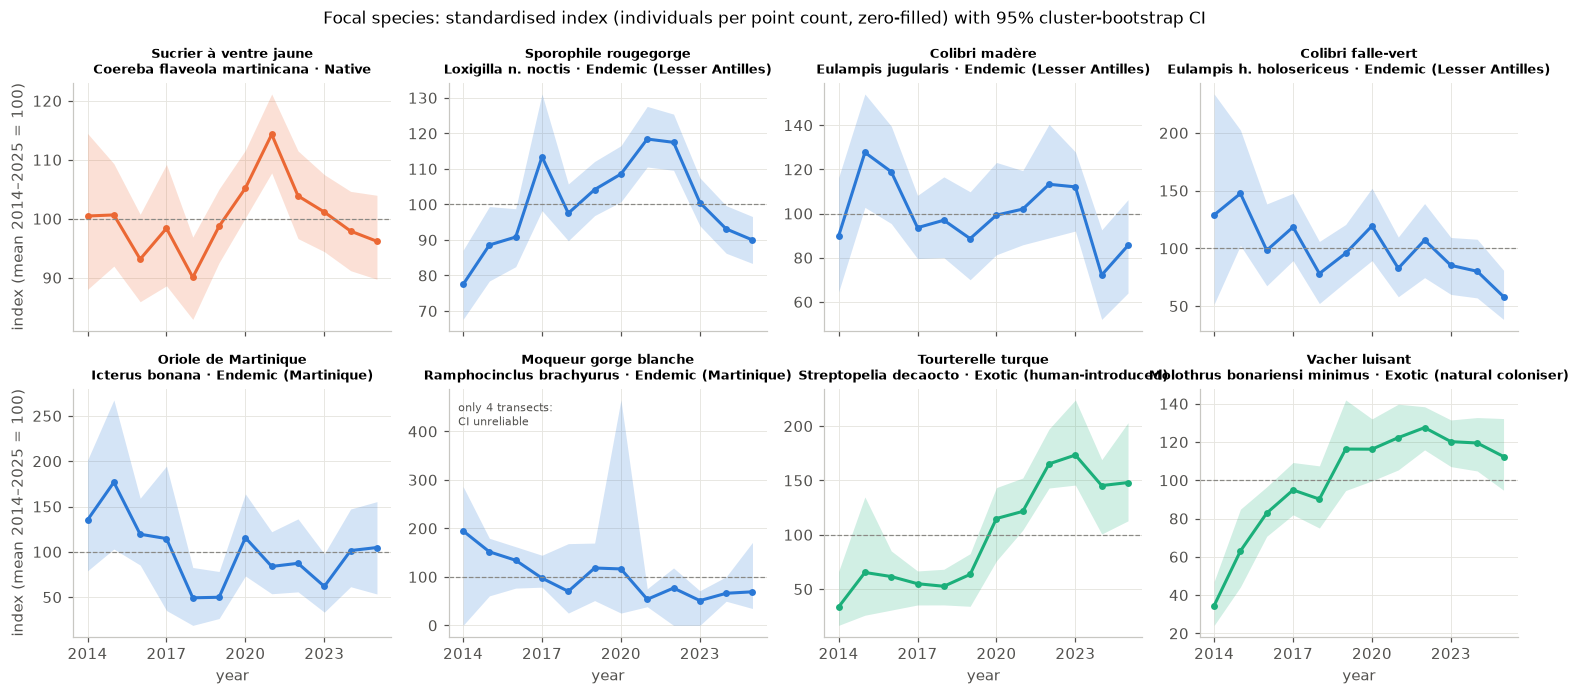

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex=True)
for ax, sp in zip(axes.flat, FOCAL):
    d = series[sp]; g = info.loc[sp, "group"]
    col = plots.STATUS_COLORS.get(g, plots.GREY)
    ax.fill_between(YRS, d["low"], d["high"], color=col, alpha=0.2, lw=0)
    ax.plot(YRS, d["index100"], marker="o", markersize=3.5, color=col)
    ax.axhline(100, color=plots.GREY, lw=0.8, ls="--")
    ax.set_title(f"{sp}\n{info.loc[sp, 'name_sci']} · {info.loc[sp, 'status']}", fontsize=8.5)
    ax.set_xticks(YRS[::3])
    if sp == "Moqueur gorge blanche":
        ax.text(0.03, 0.95, f"only {info.loc[sp, 'transects']} transects:\nCI unreliable", transform=ax.transAxes,
                fontsize=7.5, va="top", color=plots.INK2)
for ax in axes[:, 0]:
    ax.set_ylabel("index (mean 2014–2025 = 100)")
for ax in axes[-1]:
    ax.set_xlabel("year")
fig.suptitle("Focal species: standardised index (individuals per point count, zero-filled) with 95% cluster-bootstrap CI",
             fontsize=11)
fig.tight_layout()
plots.savefig(fig, "fig11_focal_species")
plt.show()

### 2.1 Occurrence rates: Wilson vs cluster bootstrap
The occurrence rate (share of point counts with the species) is a Bernoulli MLE. The Wilson
interval assumes independent point counts; we saw in notebook 02 that detections at
neighbouring points are strongly dependent.

In [5]:
rows = []
j = YRS.index(2025)
for sp in FOCAL:
    est, reps = S.occurrence(P, sp, W, TR, YRS)
    n = (P["year"] == 2025).sum()
    wl, wh = S.wilson(est[j], n)
    bl, bh = np.quantile(reps[:, j], [0.025, 0.975])
    rows.append({"species": sp, "occurrence 2025 (%)": 100 * est[j],
                 "Wilson CI width (pts)": 100 * (wh - wl), "cluster bootstrap CI width (pts)": 100 * (bh - bl),
                 "ratio": (bh - bl) / (wh - wl)})
occ_tab = pd.DataFrame(rows).set_index("species")
occ_tab.to_csv(C.RES_DIR / "table16_occurrence_ci.csv")
occ_tab.round(2)

,occurrence 2025 (%),Wilson CI width (pts),cluster bootstrap CI width (pts),ratio
species,,,,
Sucrier à ventre jaune,75.43,4.72,8.30,1.76
Sporophile rougegorge,63.46,5.27,10.35,1.96
Colibri madère,10.41,3.35,7.39,2.21
Colibri falle-vert,3.13,1.93,2.44,1.27
Oriole de Martinique,1.56,1.39,2.19,1.58
Moqueur gorge blanche,1.02,1.14,2.11,1.86
Tourterelle turque,10.64,3.38,8.82,2.60
Vacher luisant,20.34,4.41,8.87,2.01


**Reading.** The Wilson interval is 1.3–2.6 times too narrow for these species. This is not a flaw
of the Wilson formula but of its independence assumption; the cluster bootstrap is used for all
species-level intervals.

## 3. Global rate of change and trend classes

Two estimators of the annual rate of change (% per year):

* **A — annual log-linear**: slope of log(annual index) on year. Simple and standard, but
  ignores which transects and which observers produced each year's index.
* **B — visit-level regression** (main): per-point count of the species in each visit regressed
  on year with transect fixed effects, survey conditions and observer fixed effects (the M4a
  specification of notebook 02, on the raw count scale so that zeros are allowed); rate = year
  coefficient / mean count.

**Classes** (from the 95 % CI of the rate, following the Pan-European Common Bird Monitoring
Scheme logic): *strong increase* (CI entirely above +5 %/yr), *moderate increase* (CI above 0),
*stable* (CI includes 0 and lies within ±5 %/yr), *uncertain* (CI includes 0 but extends beyond
±5 %/yr), *moderate decline*, *steep decline*. Species with fewer than 10 transects are not
classified.

In [6]:
vv = v.merge(P.groupby("visit_id")[analysed].sum().reset_index(), on="visit_id")
vv[analysed] = vv[analysed].div(vv["n_points"], axis=0)     # individuals per point count in the visit
rows = []
for k, sp in enumerate(analysed):
    est, reps = S.annual_index_series(P, sp, W, TR, YRS)
    a, alo, ahi, drop = S.rate_annual_loglinear(est, reps, YRS)
    b, blo, bhi, bse = S.rate_visit_model(vv, sp, COND, B=B, seed=C.SEED + k)
    rows.append({"species": sp, "status": info.loc[sp, "status"], "group": info.loc[sp, "group"],
                 "transects": info.loc[sp, "transects"], "detections": info.loc[sp, "detections"],
                 "A_rate": a, "A_low": alo, "A_high": ahi, "A_dropped_reps": drop,
                 "B_rate": b, "B_low": blo, "B_high": bhi, "B_se": bse})
rates = pd.DataFrame(rows).set_index("species")
rates["class_B"] = [S.trend_class(l, h) if t >= 10 else "not classified (< 10 transects)"
                    for l, h, t in zip(rates["B_low"], rates["B_high"], rates["transects"])]
rates["class_A"] = [S.trend_class(l, h) if t >= 10 else "not classified (< 10 transects)"
                    for l, h, t in zip(rates["A_low"], rates["A_high"], rates["transects"])]
cls = rates["transects"] >= 10
shr, w_, tau2, mu = S.shrink(rates.loc[cls, "B_rate"], rates.loc[cls, "B_se"])
rates.loc[cls, "B_rate_shrunk"] = shr
rates.loc[cls, "shrink_weight"] = w_
rates = rates.sort_values("B_rate")
rates.to_csv(C.RES_DIR / "table17_species_rates.csv")
print(f"Empirical-Bayes shrinkage: between-species SD of true rates tau = {np.sqrt(tau2):.2f} %/yr, "
      f"pooled mean {mu:.2f} %/yr")
print("\nClasses (estimator B):"); print(rates.loc[cls, "class_B"].value_counts().to_string())
print(f"\nSpecies whose class differs between A and B: {(rates.loc[cls, 'class_A'] != rates.loc[cls, 'class_B']).sum()} of {cls.sum()}")
rates[["status", "transects", "A_rate", "A_low", "A_high", "B_rate", "B_low", "B_high", "B_rate_shrunk", "class_B", "class_A"]].round(2)

Empirical-Bayes shrinkage: between-species SD of true rates tau = 2.37 %/yr, pooled mean 0.25 %/yr

Classes (estimator B):
class_B
stable               11
uncertain            10
moderate increase     8
moderate decline      5

Species whose class differs between A and B: 15 of 34


,status,transects,A_rate,A_low,A_high,B_rate,B_low,B_high,B_rate_shrunk,class_B,class_A
species,,,,,,,,,,,
Moqueur gorge blanche,Endemic (Martinique),4,-9.20,-12.72,-5.36,-11.42,-28.53,-0.73,NaN,not classified (< 10 transects),not classified (< 10 transects)
Sporophile curio,Exotic (human-introduced),34,-0.70,-7.24,8.50,-6.01,-12.63,-0.31,-2.01,moderate decline,uncertain
Colibri falle-vert,Endemic (Lesser Antilles),59,-5.22,-9.29,-0.43,-3.43,-7.80,0.77,-1.78,uncertain,moderate decline
Coulicou manioc,Native,62,-1.26,-3.44,1.00,-2.70,-5.64,-0.04,-1.95,moderate decline,stable
Colibri madère,Endemic (Lesser Antilles),59,-1.69,-4.58,1.15,-2.34,-5.35,0.49,-1.61,uncertain,stable
Oriole de Martinique,Endemic (Martinique),35,-3.89,-8.10,0.99,-2.12,-7.66,3.86,-0.70,uncertain,uncertain
Moqueur grivotte,Endemic (Lesser Antilles),62,-0.77,-3.21,1.98,-1.81,-3.68,-0.11,-1.53,moderate decline,stable
Colibri huppé,Endemic (Lesser Antilles),65,-1.09,-2.96,0.92,-1.75,-3.63,0.02,-1.48,stable,stable
Sporophile cici,Native,65,-1.93,-3.60,-0.25,-1.62,-3.17,-0.05,-1.43,moderate decline,moderate decline


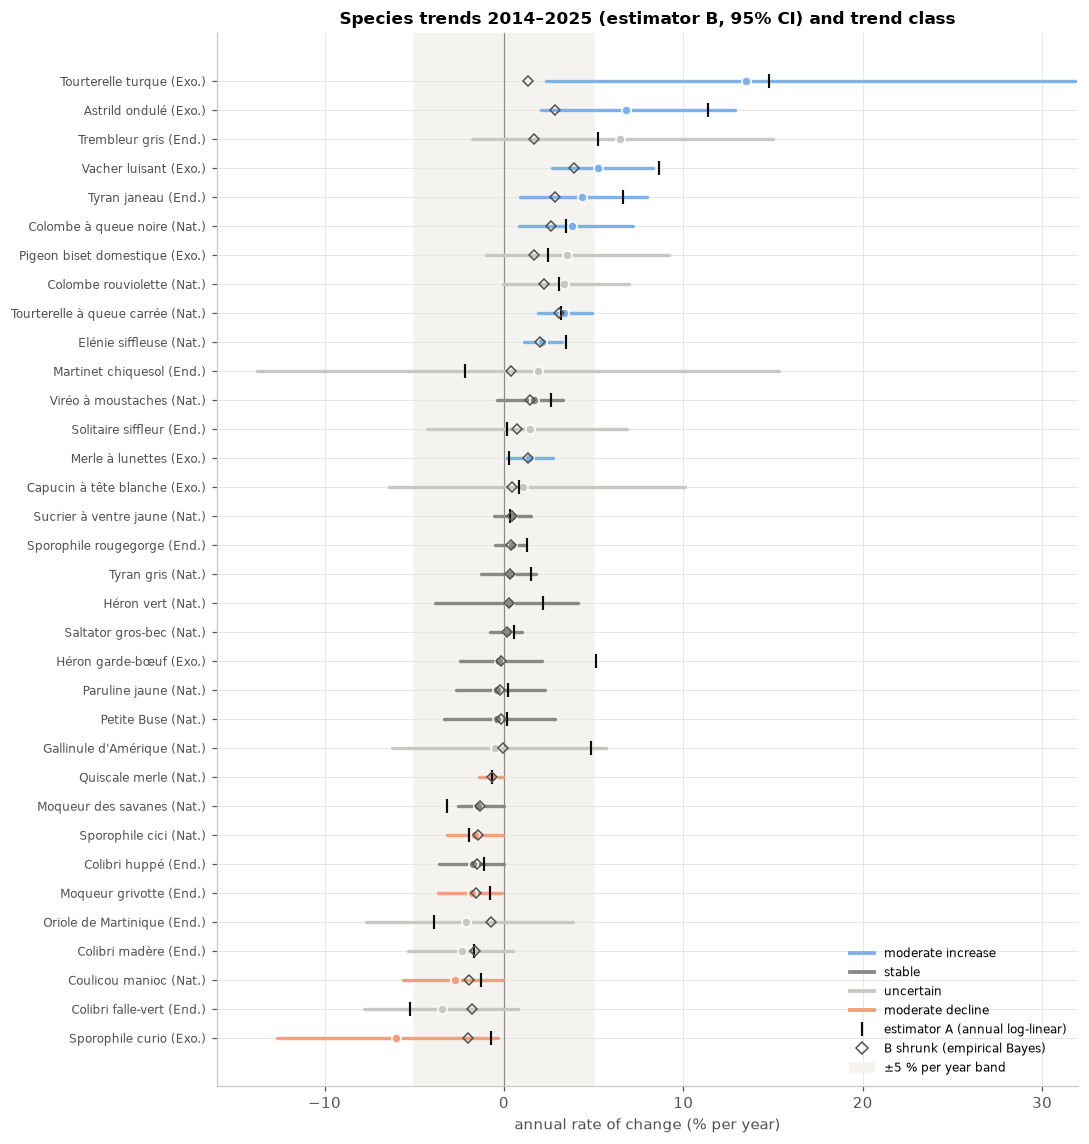

In [7]:
cl_col = {"strong increase": plots.PALETTE[0], "moderate increase": "#7fb0ea", "stable": plots.GREY,
          "uncertain": "#c8c7c2", "moderate decline": "#f0a07e", "steep decline": plots.PALETTE[1]}
rp = rates[rates["transects"] >= 10].sort_values("B_rate")
fig, ax = plt.subplots(figsize=(10, 10.5))
yy = np.arange(len(rp))
ax.axvspan(-5, 5, color="#f4f3ef", zorder=0)
ax.axvline(0, color=plots.GREY, lw=0.8)
for i, (sp, r) in enumerate(rp.iterrows()):
    col = cl_col[r["class_B"]]
    ax.plot([r["B_low"], r["B_high"]], [i, i], color=col, lw=2.2, solid_capstyle="round")
    ax.plot(r["B_rate"], i, "o", color=col, markersize=6, markeredgecolor="white")
    ax.plot(r["A_rate"], i, marker="|", color=plots.INK, markersize=9, mew=1.4)
    ax.plot(r["B_rate_shrunk"], i, marker="D", markerfacecolor="none", markeredgecolor=plots.INK2, markersize=4.5)
labels = [f"{sp} ({info.loc[sp, 'group'][:3]}.)" for sp in rp.index]
ax.set_yticks(yy, labels, fontsize=8)
ax.set_xlim(-16, 32)
ax.set(xlabel="annual rate of change (% per year)", title="Species trends 2014–2025 (estimator B, 95% CI) and trend class")
handles = [Line2D([], [], color=c, lw=2.5, label=k) for k, c in cl_col.items() if k in set(rp["class_B"])]
handles += [Line2D([], [], marker="|", ls="", color=plots.INK, markersize=9, mew=1.4, label="estimator A (annual log-linear)"),
            Line2D([], [], marker="D", ls="", markerfacecolor="none", markeredgecolor=plots.INK2, label="B shrunk (empirical Bayes)"),
            Patch(color="#f4f3ef", label="±5 % per year band")]
ax.legend(handles=handles, loc="lower right", fontsize=8)
fig.tight_layout()
plots.savefig(fig, "fig12_species_trends")
plt.show()

**Reading.**

* **Classes (estimator B, 34 species).** 8 moderate increases, 5 moderate declines, 11 stable,
  10 uncertain (intervals too wide to conclude). No species has its whole interval beyond ±5 %
  per year under B; under A, Tourterelle turque and Vacher luisant would be "strong increases".
* **Who increases.** Exotic or colonising species dominate the top of the ranking —
  Tourterelle turque (*Streptopelia decaocto*, ≈ +13 %/yr), Astrild ondulé (≈ +7 %/yr),
  Vacher luisant (*Molothrus bonariensis*, ≈ +5 %/yr), Merle à lunettes — together with native
  doves (Tourterelle à queue carrée, Colombe à queue noire), Elénie siffleuse and the endemic
  Tyran janeau.
* **Who decreases.** Negative estimates cluster among **endemic** species: all three
  hummingbirds (Colibri falle-vert ≈ −3.4, Colibri madère ≈ −2.3, Colibri huppé ≈ −1.8 %/yr),
  Moqueur grivotte (moderate decline), and both Martinique endemics (Oriole de Martinique
  ≈ −2 %/yr, uncertain; Moqueur gorge blanche, index falling from ≈ 195 to ≈ 70, not classified
  because it occurs on only 4 transects).
* **The two estimators disagree for 15 of 34 species.** Accounting for transects and observers
  (B) moves several species from "increase" to "stable" (Tyran gris, Sporophile rougegorge,
  Viréo à moustaches) and pulls Héron garde-bœuf from +5 % to ≈ 0: naive species trends inherit
  the effort and observer biases documented in notebooks 01–02.
* **Many intervals at once.** With 34 species, one or two 95 % intervals could exclude zero by
  chance alone even if nothing changed. Thirteen do, so the overall pattern is real, but
  borderline individual cases (e.g. Quiscale merle, −0.7 % with upper limit −0.04 %) should not
  be over-interpreted.
* **Shrinkage as a sensitivity check.** Pulling each rate towards the community mean
  in proportion to its imprecision (empirical Bayes, between-species SD ≈ 2.4 %/yr) barely moves
  precisely estimated species but shrinks imprecise ones strongly — Tourterelle turque from
  +13.5 % to +1.3 %. Shrinkage assumes species are exchangeable draws from one distribution; an
  invading species is not, so here shrinkage would trade variance for a large bias. We report it
  but do not use it for classification.

## 4. Which species drive the rise of exotics?

In [8]:
exo = info.index[info["group"].eq("Exotic")].tolist()
Pe = S.point_species_table(sp_rec, point_visits, exo)
early, late = Pe["year"].between(2014, 2016), Pe["year"].between(2023, 2025)
comm_tot = rec[rec["status_group"].ne("Seabird")].groupby("year")["count"].sum()
drv = pd.DataFrame({
    "status": info.loc[exo, "status"],
    "ind_per_point_2014_16": Pe.loc[early, exo].mean(),
    "ind_per_point_2023_25": Pe.loc[late, exo].mean(),
})
drv["change"] = drv["ind_per_point_2023_25"] - drv["ind_per_point_2014_16"]
drv["share_of_exotic_change_pct"] = drv["change"] / drv["change"].sum() * 100
drv = drv.sort_values("change", ascending=False)
drv.to_csv(C.RES_DIR / "table18_exotic_drivers.csv")
drv.round(3).head(10)

,status,ind_per_point_2014_16,ind_per_point_2023_25,change,share_of_exotic_change_pct
Tourterelle turque,Exotic (human-introduced),0.130,0.363,0.233,36.127
Astrild ondulé,Exotic (human-introduced),0.137,0.341,0.204,31.602
Vacher luisant,Exotic (natural coloniser),0.203,0.376,0.173,26.804
Héron garde-bœuf,Exotic (natural coloniser),0.181,0.290,0.108,16.778
Pigeon biset domestique,Exotic (human-introduced),0.283,0.322,0.039,6.031
Amazone aourou,Exotic (human-introduced),0.024,0.053,0.028,4.405
Tisserin gendarme,Exotic (human-introduced),0.025,0.046,0.021,3.330
Tourterelle oreillarde,Exotic (natural coloniser),0.000,0.000,0.000,0.000
Coq bankiva,Exotic (human-introduced),0.000,0.000,-0.000,-0.011
Bengali rouge,Exotic (human-introduced),0.001,0.000,-0.001,-0.104


**Reading.** Four species explain essentially all of the rise in exotic individuals between
2014–2016 and 2023–2025: Tourterelle turque (≈ 36 % of the increase), Astrild ondulé (≈ 32 %),
Vacher luisant (≈ 27 %) and Héron garde-bœuf (≈ 17 %); the most widespread exotic, Merle à
lunettes, contributes little or negatively. The composition change of notebook 02 is therefore
driven by a few recent colonisers of open and human-modified habitats, not by a general shift.

## 5. Possible explanations (hypotheses, not conclusions)

**Ecological hypotheses**

1. **Ongoing invasion of the Eurasian Collared-Dove.** Its index rises about fivefold (≈ 34 in
   2014 → ≈ 170 in 2022–2023, mean = 100). The species is a recent coloniser of the French Antilles
   (Barré et al., *J. Caribb. Ornithol.*); an expanding invader is expected to grow quickly before
   levelling off, which matches the plateau after 2022.
2. **Brood parasitism pressure on the Martinique Oriole.** The Shiny Cowbird, a brood parasite,
   increases by ≈ 5 % per year, and is reported to parasitise roughly three quarters of Martinique
   Oriole nests each year; the Oriole is listed as Vulnerable (Wikipedia, *Martinique oriole*).
   The Oriole's negative (though uncertain) trend is consistent with rising parasitism, a
   hypothesis that nest monitoring could test directly.
3. **Endemic hummingbirds.** All three decline. Candidate drivers include hurricane damage to
   flowering resources — the indices of Colibri falle-vert and of the Oriole show a marked dip in
   2018, the year after Hurricane Maria (September 2017), which caused short-term declines of
   forest birds on neighbouring Dominica (Univ. of Manchester study) — and changes in flowering
   linked to drought or land use. With 12 years the hurricane signal cannot be separated from
   year-to-year noise.
4. **Martinique (White-breasted) Thrasher.** Endangered, with an estimated 133–267 individuals
   restricted to about 5 km² of the Caravelle peninsula, threatened by habitat loss and by
   introduced rats and mongooses (Wikipedia, *Martinique thrasher*). Our four transects in its
   range show a falling index; the estimate is fragile, but the signal is worrying for a species
   this small.

**Operational hypotheses**

5. **Detection rather than abundance.** Notebook 01 showed a growing share of birds detected by
   ear and beyond 100 m. Loud, far-carrying species (doves, cowbird) benefit most from such a shift,
   so part of their increase may be detection; small, quiet species (hummingbirds) would not.
6. **Observer turnover.** Estimators A and B disagree for 15 species: species trends are sensitive
   to who counted.
7. **Flocking species** (Héron garde-bœuf, Astrild ondulé, Pigeon biset) produce occasional very
   large counts; their indices are dominated by a few points, hence wide intervals.

*Sources:* [Martinique oriole (Wikipedia)](https://en.wikipedia.org/wiki/Martinique_oriole);
[Martinique thrasher (Wikipedia)](https://en.wikipedia.org/wiki/Martinique_thrasher);
[Barré et al., Status of the Eurasian Collared-Dove in the French Antilles, J. Caribb. Ornithol.](https://jco.birdscaribbean.org/index.php/jco/article/view/782);
[The short-term impacts of Hurricane Maria on the forest birds of Dominica (Univ. of Manchester)](https://research.manchester.ac.uk/en/publications/the-short-term-impacts-of-hurricane-maria-on-the-forest-birds-of-/).

## 6. Limitations of the species-level estimates

* **Detectability differs between species.** Indices measure detected birds:
  P(recorded) = P(present) × P(detected | present). Loud, far-carrying species (doves,
  cowbird) gain most from the growing share of distant detections (notebook 01); quiet
  species such as hummingbirds do not. Observer and site effects are controlled,
  species-specific detectability is not.
* **Model assumptions of estimator B.** A linear model on raw per-point counts assumes additive
  effects and constant variance, which skewed, zero-heavy counts violate; the cluster bootstrap
  keeps the intervals honest but the estimator is not efficient for rare species.
* **Species on few transects.** With 4 (Moqueur gorge blanche), 14 (Solitaire siffleur)
  or 15 (Trembleur gris) transects, the transect bootstrap has little to resample;
  their intervals are indicative only.
* **Unidentified hummingbirds.** 1,161 records identified only to genus/family (mostly
  Trochilidae) are not attributed to species. If identification practice changed over
  time, the hummingbird declines could partly reflect it. The selection rule also
  excludes rare species, which are often the most threatened.